# Лабораторна 3. Токенізація та трансформери

У цій лабораторній роботі ви пройдете шлях від механіки токенізації до практичного використання готових мовних моделей:

- алгоритми токенізації (BPE, WordPiece, Unigram) — натренуєте всі три на власному тексті;
- mini-GPT з нуля — повторите тренування трансформера на своєму датасеті;
- готові моделі для різних NLP-задач — класифікація, генерація, переклад, Q&A та інше через `pipeline()`;
- порівняння кількох моделей на одній задачі;
- творчий застосунок на основі готової моделі.

Демо-ноутбук лекції 4 (`ransformers_demo.ipynb`) — основа для секцій 2-3, звертайтесь до нього як до довідника. Розділи 1 і 4 спираються на офіційний [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/en/chapter1/1) — читайте відповідні розділи курсу перед виконанням, посилання додані в кожній секції.

## Матеріали

- [3Blue1Brown — Transformers, the tech behind LLMs](https://www.youtube.com/watch?v=wjZofJX0v4M)
- [3Blue1Brown — Attention in transformers, step-by-step](https://www.youtube.com/watch?v=eMlx5fFNoYc)
- [3Blue1Brown — How might LLMs store facts](https://www.youtube.com/watch?v=9-Jl0dxWQs8)
- [Hugging Face LLM Course — Chapter 1: Transformer Models](https://huggingface.co/learn/llm-course/en/chapter1/1)
- [Hugging Face LLM Course — Chapter 2: Using Transformers](https://huggingface.co/learn/llm-course/en/chapter2/1)
- [Hugging Face LLM Course — Chapter 6: The Tokenizers library](https://huggingface.co/learn/llm-course/en/chapter6/1)

## 0. Опрацюйте демо-ноутбук лекції 4

Прогляньте пояснення і запустіть усі клітинки демо-ноутбука.

Після цього дайте відповідь на запитання нижче.

### 0.1. Теоретичні питання (якщо потрібно дописати якийсь код, то в блоці "Мої відповіді наведіть відповідний код")

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?

Якщо передати всі вірші одним рядком, BPE навчатиметься на спільному тексті без явного розмежування між окремими творами. У результаті алгоритм може формувати токени, що охоплюють фрагменти на межах сусідніх віршів, якщо між ними немає відповідних роздільників. Сам алгоритм не обов'язково завершиться з помилкою, однак отриманий словник може відрізнятися від очікуваного. Тому важливо враховувати структуру корпусу та правильно позначати межі текстів.

2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))

Нормалізація  — попереднє перетворення тексту до узгодженого формату, наприклад зміна регістру або нормалізація символів.
Попереднє розбиття — поділ тексту на початкові фрагменти за визначеними правилами, наприклад на слова, числа та розділові знаки.
Модель токенізації — перетворення отриманих фрагментів на токени відповідно до обраного алгоритму, наприклад BPE, та визначення їхніх числових ідентифікаторів.
Постобробка — остаточне формування послідовності, зокрема додавання спеціальних токенів початку або кінця, якщо це передбачено конфігурацією токенізатора.

2. Що таке `"<unk>", "<eos>"` в 2.1.?

`<unk>` unknown — спеціальний токен, який позначає невідомий елемент тексту, якщо токенізатор не може представити його за допомогою доступних токенів.
`<eos>` end of sequence — спеціальний маркер завершення послідовності, який допомагає моделі визначати кінець окремого тексту.

3. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).

Після зменшення словника з 16 000 до 6 000 токенів загальна кількість токенів у корпусі збільшилася з 18 421 968 до 21 041 508. Частка `<unk>` в обох випадках залишилася нульовою.

Це пов'язано з тим, що менший словник містить менше довгих складених токенів, тому текст частіше поділяється на коротші фрагменти. Оскільки базові символи все ще можна представити доступними токенами, кількість `<unk>` не обов'язково зростає. Проте загальна довжина послідовностей збільшується, і за незмінного CONTEXT_LEN модель може враховувати меншу кількість символів тексту в межах одного контексту.

4. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?

`<eos>` позначає кінець одного вірша, якщо це прибрати то кінець поточного вірша і початок наступного злипнуться в один суцільний текст.

5. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?

`train_data` і `val_data` — це одновимірні тензори `PyTorch` із типом даних int64. Вони містять числові ідентифікатори токенів, отримані після токенізації навчального та валідаційного текстів.

Кожне число відповідає певному токену зі словника BPE. `train_data` використовується для навчання моделі, а `val_data` — для перевірки її здатності працювати з даними, які не використовувалися безпосередньо для оновлення параметрів.

6. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.

`assert torch.equal(x[:, 1:], y[:, :-1]), "error"`

7. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?

Нижньотрикутна маска дає змогу кожній позиції враховувати поточний і попередні токени, водночас блокуючи доступ до майбутніх позицій. Це необхідно для авторегресивної моделі, яка має прогнозувати наступний токен лише на основі вже доступного контексту.
Якщо прибрати маску, під час навчання модель зможе отримувати інформацію про майбутні токени. Це створить витік цільової інформації та призведе до невідповідності між умовами навчання й реальної генерації тексту.

8. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.

Найкращий і останній чекпоінти збігаються, якщо найменше значення `val_loss` досягнуто на останній ітерації, для якої зберігався стан моделі. Якщо мінімальна помилка спостерігалася раніше, найкращим буде попередній чекпоінт.

10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?

Після зміни `EVAL_INTERVAL` із 250 на 50 оцінювання моделі виконується частіше, завдяки чому можна детальніше простежити зміну значень помилки під час навчання. Графік стає інформативнішим, але не обов'язково гладкішим, оскільки на ньому відображається більше короткочасних коливань.

Час виконання трохи скоротився: 2.2 хвилини замість 2.8 хвилини. Отже, у цьому випадку частіше оцінювання було доцільним. Водночас надмірне зменшення інтервалу може збільшити обчислювальні витрати через часті виклики `estimate_loss()` на `EVAL_ITERS` батчах, не забезпечуючи суттєвого покращення аналізу навчання.

11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.

Параметр temperature регулює випадковість вибору наступного токена. Перед застосуванням softmax логіти діляться на значення температури.

За низької температури, наприклад `temperature=0.2`, відмінності між імовірностями посилюються, тому модель частіше вибирає найімовірніші токени. За вищої температури, наприклад `temperature=1.4`, розподіл імовірностей стає більш рівномірним, що збільшує шанси менш імовірних варіантів. За дуже високої температури вибір наближається до випадкового, через що текст може втрачати логічну послідовність.

12. За що саме відповідає параметр `top_p`?

Параметр top_p реалізує вибірку за ядром. Він визначає мінімальний набір найімовірніших токенів, сумарна ймовірність яких досягає заданого порога, після чого інші токени виключаються з вибору.
За меншого значення top_p модель зазвичай обирає з вужчого набору варіантів, що робить генерацію передбачуванішою. За більшого значення доступний ширший набір токенів, тому текст може бути різноманітнішим.

13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

Коли `enable_thinking=False`, модель генерує відповідь без окремого блоку міркувань.
Після зміни параметра на `enable_thinking=True` вона спочатку формує блок think, а потім переходить до основного тексту.

---
## 1. Свій датасет

Знайдіть **свій** українськомовний текстовий корпус, достатній за обсягом для mini-GPT — наприклад, на [Hugging Face Datasets](https://huggingface.co/datasets?language=language:uk) або на [Kaggle](https://www.kaggle.com/datasets?search=ukrainian). Жанр і епоха — на ваш вибір (новини, художня література, вікіпедія, форуми, судові рішення тощо), головне — одна мова (українська) і достатньо тексту, щоб токенізатор і модель побачили бодай прості закономірності.

⚠️ Якщо датасет великий (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`), інакше отримаєте помилку нестачі пам'яті (out of memory, OOM).

⚠️ Якщо датасет доступний лише через `streaming=True` (наприклад, через розмір) — `load_dataset(..., streaming=True).take(N)` повертає `IterableDataset`, у якого **нема** `.to_pandas()` і `len()`. Спершу матеріалізуйте вибірку в список, а вже потім — у `DataFrame`:
```python
rows = list(streamed_ds)
poems_df = pd.DataFrame(rows)
```

In [ ]:
!pip install "transformers[sentencepiece]==5.18.0"

In [35]:
import os

BASE_DIR = os.path.join(os.getcwd(), "lab3Tasks")
os.makedirs(BASE_DIR, exist_ok=True)

ARTIFACT_DIR = BASE_DIR

RUNS_DIR = os.path.join(BASE_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)

print("Артефакти зберігаються в:", ARTIFACT_DIR)

Артефакти зберігаються в: d:\Downloads\lab3\lab3Tasks


In [36]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Використовуємо:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Використовуємо: cuda
GPU: NVIDIA GeForce RTX 4070 Ti SUPER


In [37]:
import pandas as pd
from datasets import load_dataset

dataset = load_dataset(
    "anon-researcher-ua/ua-codeforces-cots-open-r1-for-training",
    split="train"
)

print("Загальна кількість записів:", len(dataset))
print("Доступні колонки:", dataset.column_names)

ukrainian_dataset = dataset.filter(
    lambda row: row["reasoning_language"] == "Ukrainian"
)

filtered_df = pd.DataFrame(ukrainian_dataset)

poems_df = pd.DataFrame({
    "context_poem": (
        filtered_df["user"].fillna("").astype(str).str.strip()
        + "\n\n"
        + filtered_df["analysis"].fillna("").astype(str).str.strip()
    )
})

poems_df["context_poem"] = poems_df["context_poem"].str.strip()
poems_df = poems_df[
    poems_df["context_poem"].str.replace("\n", "").str.strip() != ""
].reset_index(drop=True)

total_chars = poems_df["context_poem"].str.len().sum()

print("\nКількість записів українською:", len(ukrainian_dataset))
print("Кількість підготовлених текстів:", len(poems_df))
print(f"Загальна кількість символів: {total_chars:,}")

if not poems_df.empty:
    print("\nПриклад підготовленого тексту:\n")
    print(poems_df["context_poem"].iloc[0])
else:
    print("Після фільтрації не залишилося текстів для навчання.")


Загальна кількість записів: 4100
Доступні колонки: ['task_id', 'reasoning_language', 'user', 'analysis', 'final', 'reasoning_effort', 'type', 'messages_gpt', 'messages_qwen']

Кількість записів українською: 2612
Кількість підготовлених текстів: 2612
Загальна кількість символів: 30,795,427

Приклад підготовленого тексту:

Вам надано задачу зі спортивного програмування.

Проаналізуйте максимальні вхідні обмеження та визначте оптимальний алгоритмічний підхід і структури даних, необхідні для обробки найбільших можливих тестів у межах лімітів часу та пам’яті; потім поясніть, чому обрана стратегія реалізації є найефективнішою. Міркуйте крок за кроком щодо вашого рішення, після чого наведіть повну реалізацію мовою Python 3, ретельно оптимізовану як за швидкістю, так і за використанням пам’яті.

Ваш розв’язок має зчитувати вхід зі стандартного вводу (input()) та виводити результат у стандартний вивід (print()).
Не додавайте жодних налагоджувальних повідомлень чи зайвого тексту.

Розмістіть фін

In [38]:
texts_list = poems_df["context_poem"].dropna().tolist()
corpus_text = "\n\n".join(texts_list)
corpus_length = len(corpus_text)
print(f"Загальна довжина корпусу: {corpus_length:,} символів")
preview_length = 100
print(f"\nПочаток корпусу (перші {preview_length} символів):\n")
print(corpus_text[:preview_length])


Загальна довжина корпусу: 30,800,649 символів

Початок корпусу (перші 100 символів):

Вам надано задачу зі спортивного програмування.

Проаналізуйте максимальні вхідні обмеження та визна


In [39]:
word_list = corpus_text.split()
unique_words = set(word.lower() for word in word_list)
total_words = len(word_list)
unique_word_count = len(unique_words)
print(f"Загальна кількість слів: {total_words:,}")
print(f"Кількість різних слів: {unique_word_count:,}")
preview_length = 100
print(f"\nПриклад тексту з корпусу (перші {preview_length} символів):\n")
print(corpus_text[:preview_length])

Загальна кількість слів: 4,958,425
Кількість різних слів: 135,236

Приклад тексту з корпусу (перші 100 символів):

Вам надано задачу зі спортивного програмування.

Проаналізуйте максимальні вхідні обмеження та визна


---
## 2. Токенізатори: BPE, WordPiece, Unigram

Демо тренує лише BPE. У цій секції ви натренуєте й порівняєте всі три основні алгоритми токенізації на **своєму** тексті.

Матеріал — офіційний [Hugging Face LLM Course, розділ 6](https://huggingface.co/learn/llm-course/en/chapter6/1). Пройдіть і повторіть на своїх даних:

1. **[6.2. Тренування нового токенізатора на основі старого](https://huggingface.co/learn/llm-course/en/chapter6/2)** — найпростіший шлях: `tokenizer.train_new_from_iterator(...)` на основі архітектури готового токенізатора (наприклад, `Qwen/Qwen2.5-0.5B-Instruct`). Зробіть це як розминку перед ручними варіантами нижче.
2. **[6.5. Алгоритм BPE](https://huggingface.co/learn/llm-course/en/chapter6/5)** — повторіть покрокову реалізацію з туторіалу на своєму тексті, повністю вручну або за допомогою бібліотеки `tokenizers`.
3. **[6.6. Алгоритм WordPiece](https://huggingface.co/learn/llm-course/en/chapter6/6)** — так само.
4. **[6.7. Алгоритм Unigram](https://huggingface.co/learn/llm-course/en/chapter6/7)** — так само.

### 1.1. Порівняння

Для однакового `vocab_size` (візьміть, наприклад, 500 — на невеликому зразку тексту більший словник не встигне показати різницю) порівняйте три токенізатори в невеликій таблиці: розмір словника, кількість токенів на вашому зразку, скільки токенів виходить на кількох обраних словах (частотне й рідкісне — як у лекції). Коротко письмово: який алгоритм дав найкоротші послідовності на вашому тексті і чи це узгоджується з тим, що каже туторіал про природу кожного алгоритму?

In [40]:
from collections import Counter
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

VOCAB_SIZE = 500
SPECIAL_TOKENS = ["<unk>", "<eos>"]

texts = poems_df["context_poem"].dropna().tolist()
sample_texts = texts[:500]
sample_chars = sum(len(text) for text in sample_texts)

print("Кількість доступних текстів:", len(texts))
print("Розмір експериментальної вибірки:", len(sample_texts))
print(f"Загальний обсяг вибірки: {sample_chars:,} символів")

Кількість доступних текстів: 2612
Розмір експериментальної вибірки: 500
Загальний обсяг вибірки: 6,137,051 символів


In [41]:
from transformers import AutoTokenizer

base_tokenizer = AutoTokenizer.from_pretrained(
    "Qwen/Qwen2.5-0.5B-Instruct"
)

custom_qwen_tokenizer = base_tokenizer.train_new_from_iterator(
    iter(sample_texts),
    vocab_size=VOCAB_SIZE
)

tokenizer_vocab_size = len(custom_qwen_tokenizer)
print("Кількість токенів у новому словнику:", tokenizer_vocab_size)
example = sample_texts[0][:100]
print("\nТекст для перевірки:\n")
print(example)
tokens = custom_qwen_tokenizer.tokenize(example)
print("\nРезультат токенізації:\n", tokens)

Кількість токенів у новому словнику: 508

Текст для перевірки:

Вам надано задачу зі спортивного програмування.

Проаналізуйте максимальні вхідні обмеження та визна

Результат токенізації:
 ['Ð', 'Ĵ', 'Ð°', 'Ð¼', 'ĠÐ½', 'Ð°Ð´', 'Ð°', 'Ð½Ð¾', 'ĠÐ·', 'Ð°Ð´', 'Ð°Ñĩ', 'Ñĥ', 'ĠÐ·', 'Ñĸ', 'ĠÑģ', 'Ð¿', 'Ð¾ÑĢ', 'ÑĤÐ¸', 'Ð²', 'Ð½Ð¾Ð³Ð¾', 'ĠÐ¿ÑĢ', 'Ð¾Ð³', 'ÑĢÐ°', 'Ð¼', 'ÑĥÐ²Ð°', 'Ð½', 'Ð½Ñı', '.ĊĊ', 'Ð', 'Ł', 'ÑĢ', 'Ð¾', 'Ð°', 'Ð½Ð°', 'Ð»Ñĸ', 'Ð·', 'Ñĥ', 'Ð¹ÑĤÐµ', 'ĠÐ¼Ð°', 'Ðº', 'ÑģÐ¸', 'Ð¼Ð°Ð»ÑĮ', 'Ð½Ñĸ', 'ĠÐ²', 'ÑħÑĸÐ´', 'Ð½Ñĸ', 'ĠÐ¾Ð±', 'Ð¼', 'Ðµ', 'Ð¶', 'ÐµÐ½Ð½Ñı', 'ĠÑĤÐ°', 'ĠÐ²Ð¸', 'Ð·', 'Ð½Ð°']


In [42]:
bpe_tokenizer = Tokenizer(
    models.BPE(unk_token="<unk>")
)
bpe_tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(
    add_prefix_space=False
)
bpe_tokenizer.decoder = decoders.ByteLevel()

bpe_trainer = trainers.BpeTrainer(
    vocab_size=VOCAB_SIZE,
    special_tokens=SPECIAL_TOKENS
)
bpe_tokenizer.train_from_iterator(
    iter(sample_texts),
    trainer=bpe_trainer
)

bpe_vocab = bpe_tokenizer.get_vocab()
vocab_count = len(bpe_vocab)

print("Кількість токенів у словнику BPE:", vocab_count)

test_text = sample_texts[0][:250]
encoded_output = bpe_tokenizer.encode(test_text)

print("\nТекст для перевірки:\n", test_text)
print("\nРезультат токенізації:\n", encoded_output.tokens)


Кількість токенів у словнику BPE: 500

Текст для перевірки:
 Вам надано задачу зі спортивного програмування.

Проаналізуйте максимальні вхідні обмеження та визначте оптимальний алгоритмічний підхід і структури даних, необхідні для обробки найбільших можливих тестів у межах лімітів часу та пам’яті; потім поясні

Результат токенізації:
 ['Ð', 'Ĵ', 'Ð°', 'Ð¼', 'ĠÐ½', 'Ð°Ð´', 'Ð°', 'Ð½Ð¾', 'ĠÐ·', 'Ð°Ð´', 'Ð°Ñĩ', 'Ñĥ', 'ĠÐ·', 'Ñĸ', 'ĠÑģÐ¿', 'Ð¾ÑĢ', 'ÑĤÐ¸', 'Ð²', 'Ð½Ð¾Ð³Ð¾', 'ĠÐ¿ÑĢ', 'Ð¾Ð³', 'ÑĢÐ°', 'Ð¼', 'ÑĥÐ²Ð°', 'Ð½', 'Ð½Ñı', '.', 'Ċ', 'Ċ', 'ÐŁ', 'ÑĢ', 'Ð¾', 'Ð°', 'Ð½Ð°', 'Ð»Ñĸ', 'Ð·', 'Ñĥ', 'Ð¹ÑĤÐµ', 'ĠÐ¼Ð°', 'ÐºÑģÐ¸', 'Ð¼Ð°Ð»ÑĮ', 'Ð½Ñĸ', 'ĠÐ²', 'ÑħÑĸÐ´', 'Ð½Ñĸ', 'ĠÐ¾Ð±', 'Ð¼', 'Ðµ', 'Ð¶', 'ÐµÐ½Ð½Ñı', 'ĠÑĤÐ°', 'ĠÐ²Ð¸', 'Ð·', 'Ð½Ð°Ñĩ', 'ÑĤÐµ', 'ĠÐ¾Ð¿', 'ÑĤÐ¸', 'Ð¼Ð°Ð»ÑĮ', 'Ð½Ð¸Ð¹', 'ĠÐ°', 'Ð»', 'Ð³', 'Ð¾', 'ÑĢÐ¸', 'ÑĤ', 'Ð¼Ñĸ', 'Ñĩ', 'Ð½Ð¸Ð¹', 'ĠÐ¿ÑĸÐ´', 'ÑħÑĸÐ´', 'ĠÑĸ', 'ĠÑģÑĤ', 'ÑĢ', 'Ñĥ', 'Ðº', 'ÑĤ', 'Ñĥ', 'ÑĢÐ¸', 'ĠÐ´', 'Ð°', 'Ð½Ð¸Ñħ', ',', 'ĠÐ½Ðµ', 'Ð¾Ð±', 'ÑħÑĸÐ´', 'Ð½Ñĸ', 'ĠÐ´Ð»Ñı'

In [43]:
wordpiece_tokenizer = Tokenizer(
    models.WordPiece(unk_token="<unk>")
)

wordpiece_tokenizer.pre_tokenizer = pre_tokenizers.BertPreTokenizer()
wordpiece_tokenizer.decoder = decoders.WordPiece(prefix="##")

wordpiece_trainer = trainers.WordPieceTrainer(
    vocab_size=VOCAB_SIZE,
    special_tokens=SPECIAL_TOKENS
)

wordpiece_tokenizer.train_from_iterator(
    iter(sample_texts),
    trainer=wordpiece_trainer
)

wordpiece_vocab = wordpiece_tokenizer.get_vocab()
wordpiece_vocab_size = len(wordpiece_vocab)

print("Кількість токенів WordPiece:", wordpiece_vocab_size)

test_text = sample_texts[0][:250]
encoded_tokens = wordpiece_tokenizer.encode(test_text).tokens

print("\nТекст для перевірки:\n", test_text)
print("\nТокени для тестового тексту:\n", encoded_tokens)

Кількість токенів WordPiece: 500

Текст для перевірки:
 Вам надано задачу зі спортивного програмування.

Проаналізуйте максимальні вхідні обмеження та визначте оптимальний алгоритмічний підхід і структури даних, необхідні для обробки найбільших можливих тестів у межах лімітів часу та пам’яті; потім поясні

Токени для тестового тексту:
 ['В', '##а', '##м', 'на', '##да', '##но', 'за', '##да', '##ч', '##у', 'з', '##і', 'с', '##п', '##о', '##р', '##ти', '##в', '##ного', 'п', '##ро', '##г', '##ра', '##му', '##ва', '##ння', '.', 'П', '##ро', '##а', '##на', '##лі', '##з', '##у', '##йте', 'ма', '##к', '##си', '##маль', '##ні', 'в', '##хід', '##ні', 'об', '##м', '##е', '##же', '##ння', 'та', 'ви', '##з', '##на', '##ч', '##те', 'о', '##п', '##ти', '##маль', '##ний', 'а', '##л', '##го', '##ри', '##т', '##мі', '##ч', '##ний', 'під', '##хід', 'і', 'с', '##т', '##ру', '##к', '##т', '##у', '##ри', 'д', '##а', '##них', ',', 'не', '##о', '##б', '##хід', '##ні', 'для', 'об', '##роб', '##ки', 'на', '##й'

In [44]:
unigram_tokenizer = Tokenizer(models.Unigram())

unigram_tokenizer.pre_tokenizer = pre_tokenizers.Metaspace(
    replacement="▁",
    prepend_scheme="always"
)

unigram_tokenizer.decoder = decoders.Metaspace(
    replacement="▁",
    prepend_scheme="always"
)

unigram_trainer = trainers.UnigramTrainer(
    vocab_size=VOCAB_SIZE,
    special_tokens=SPECIAL_TOKENS,
    unk_token="<unk>"
)

unigram_tokenizer.train_from_iterator(
    iter(sample_texts),
    trainer=unigram_trainer
)

unigram_vocab = unigram_tokenizer.get_vocab()
unigram_vocab_size = len(unigram_vocab)

print("Кількість токенів у словнику Unigram:", unigram_vocab_size)

test_text = sample_texts[0][:250]
result_tokens = unigram_tokenizer.encode(test_text).tokens

print("\nТекст для перевірки:\n", test_text)
print("\nРезультат розбиття тексту:\n", result_tokens)

Кількість токенів у словнику Unigram: 500

Текст для перевірки:
 Вам надано задачу зі спортивного програмування.

Проаналізуйте максимальні вхідні обмеження та визначте оптимальний алгоритмічний підхід і структури даних, необхідні для обробки найбільших можливих тестів у межах лімітів часу та пам’яті; потім поясні

Результат розбиття тексту:
 ['▁', 'В', 'а', 'м', '▁на', 'д', 'а', 'но', '▁за', 'д', 'а', 'ч', 'у', '▁з', 'і', '▁с', 'п', 'ор', 'ти', 'в', 'н', 'ого', '▁про', 'г', 'р', 'а', 'м', 'у', 'в', 'ання', '.\n\n', 'П', 'р', 'о', 'а', 'на', 'л', 'із', 'у', 'й', 'т', 'е', '▁максимальн', 'і', '▁вхідн', 'і', '▁обмеження', '▁та', '▁ви', 'з', 'на', 'ч', 'т', 'е', '▁оптимальн', 'ий', '▁алгоритм', 'і', 'ч', 'ний', '▁під', 'х', 'і', 'д', '▁', 'і', '▁', 'ст', 'р', 'у', 'к', 'т', 'у', 'р', 'и', '▁даних', ',', '▁не', 'о', 'б', 'х', 'і', 'д', 'ні', '▁д', 'ля', '▁обробки', '▁найбільш', 'их', '▁можлив', 'их', '▁', 'т', 'е', 'ст', 'ів', '▁у', '▁', 'м', 'е', 'ж', 'а', 'х', '▁', 'л', 'і', 'м', 'і', 'т

In [45]:
tokenizers_dict = {
    "BPE": bpe_tokenizer,
    "WordPiece": wordpiece_tokenizer,
    "Unigram": unigram_tokenizer
}

comparison_results = []

for tokenizer_name, current_tokenizer in tokenizers_dict.items():
    total_tokens = 0

    for text in sample_texts:
        encoded_text = current_tokenizer.encode(text)
        total_tokens += len(encoded_text.ids)

    comparison_results.append({
        "Алгоритм": tokenizer_name,
        "Розмір словника": len(current_tokenizer.get_vocab()),
        "Кількість токенів у зразку": total_tokens
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)

,Алгоритм,Розмір словника,Кількість токенів у зразку
0,BPE,500,3546181
1,WordPiece,500,3552855
2,Unigram,500,3483137


In [46]:
word_frequency = Counter(
    word.lower()
    for text in sample_texts
    for word in text.split()
    if word.strip()
)

frequent_word = word_frequency.most_common(1)[0][0]

single_occurrence_words = [
    word
    for word, frequency in word_frequency.items()
    if frequency == 1 and len(word) >= 5
]

rare_word = (
    single_occurrence_words[0]
    if single_occurrence_words
    else min(word_frequency, key=word_frequency.get)
)

print(f"Найчастотніше слово: {frequent_word}")
print(f"Рідкісне слово: {rare_word}")

for tokenizer_name, current_tokenizer in tokenizers_dict.items():
    common_tokens = current_tokenizer.encode(frequent_word).tokens
    uncommon_tokens = current_tokenizer.encode(rare_word).tokens

    print(f"\n--- {tokenizer_name} ---")

    print(
        f"Частотне слово: {common_tokens} "
        f"(токенів: {len(common_tokens)})"
    )
    print(
        f"Рідкісне слово: {uncommon_tokens} "
        f"(токенів: {len(uncommon_tokens)})"
    )

Найчастотніше слово: для
Рідкісне слово: **доброю**,

--- BPE ---
Частотне слово: ['Ð´', 'Ð»Ñı'] (токенів: 2)
Рідкісне слово: ['*', '*', 'Ð´', 'Ð¾Ð±', 'ÑĢ', 'Ð¾', 'Ñİ', '*', '*', ','] (токенів: 10)

--- WordPiece ---
Частотне слово: ['для'] (токенів: 1)
Рідкісне слово: ['*', '*', 'до', '##б', '##ро', '##ю', '*', '*', ','] (токенів: 9)

--- Unigram ---
Частотне слово: ['▁д', 'ля'] (токенів: 2)
Рідкісне слово: ['▁', '*', '*', 'д', 'о', 'б', 'р', 'ою', '*', '*', ','] (токенів: 11)


---
## 3. mini-GPT на своїх даних

Повторіть підхід із розділів 2-3 демо-ноутбука на своєму датасеті — не копіюйте код один в один: у вашого датасету інша колонка з текстом, інший обсяг, інший жанр/регістр мови — токенізатор і модель побачать зовсім інші закономірності, ніж на поезії з демо.

### 3.1. Корпус і токенізація

1. Завантажте свій датасет і зберіть `corpus_text` з потрібної колонки (демо 1.2).
2. Натренуйте токенізатор на своєму корпусі (демо 2.1). **Якщо ваш датасет великий** (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`). Не забудьте `<eos>` між документами (демо 2.2).
3. Спліт train/val (демо 2.3).



In [47]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

GPT_VOCAB_SIZE = 8000
SPECIAL_TOKENS = ["<unk>", "<eos>"]

texts = poems_df["context_poem"].dropna().tolist()
texts = [text.strip() for text in texts if text.strip()]

print("Кількість текстів:", len(texts))
print("Загальна кількість символів:", f"{sum(len(text) for text in texts):,}")

gpt_tokenizer = Tokenizer(
    models.WordPiece(unk_token="<unk>")
)
gpt_tokenizer.pre_tokenizer = pre_tokenizers.BertPreTokenizer()
gpt_tokenizer.decoder = decoders.WordPiece(prefix="##")

wordpiece_trainer = trainers.WordPieceTrainer(
    vocab_size=GPT_VOCAB_SIZE,
    special_tokens=SPECIAL_TOKENS,
    min_frequency=2
)
gpt_tokenizer.train_from_iterator(
    texts,
    trainer=wordpiece_trainer
)
print("Фактичний розмір словника:", gpt_tokenizer.get_vocab_size())
print("ID токена <eos>:", gpt_tokenizer.token_to_id("<eos>"))

Кількість текстів: 2612
Загальна кількість символів: 30,795,427
Фактичний розмір словника: 8000
ID токена <eos>: 1


In [48]:
import numpy as np

EOS_ID = gpt_tokenizer.token_to_id("<eos>")
assert EOS_ID is not None, "Не знайдено токен завершення <eos>"

encoded_docs = []

for text in texts:
    token_ids = gpt_tokenizer.encode(text).ids
    encoded_docs.extend(token_ids)
    encoded_docs.append(EOS_ID)

data = np.asarray(encoded_docs, dtype=np.int32)

print("Кількість токенів у словнику:", gpt_tokenizer.get_vocab_size())
print("Загальна кількість токенів корпусу:", f"{len(data):,}")
print("Тип елементів масиву:", data.dtype)
print("Початкові 30 токенів:", data[:30])

Кількість токенів у словнику: 8000
Загальна кількість токенів корпусу: 9,050,703
Тип елементів масиву: int32
Початкові 30 токенів: [1750 2090 1281  990 2199 1737   15 2211 2104 1426 1171  459 2111 1781
 2225  773  186 1939  811   13 1864  455 1068 1948 1269 1933  172 1604
 2210 1035]


### 3.2. Модель: щонайменше 2 варіанти

За зразком розділу 3 демо (`AttentionHead`, `MultiHeadAttention`, `TransformerBlock`, `MiniGPT`) — тренуйте щонайменше 2 варіанти, які відрізняються параметрами: інший `VOCAB_SIZE`, інша `CONTEXT_LEN`, інша кількість шарів/голів (`N_LAYERS`/`N_HEADS`), або інший `MAX_ITERS`. Кожен варіант логуйте в TensorBoard в окрему підпапку (як у демо 3.8), з осмисленою назвою.



In [49]:
train_ratio = 0.9
split_idx = int(data.size * train_ratio)

train_data = data[:split_idx]
val_data = data[split_idx:]

print(f"Навчальна вибірка: {train_data.shape}")
print(f"Валідаційна вибірка: {val_data.shape}")

print(f"Частка навчальних даних: {len(train_data) / len(data):.0%}")
print(f"Частка валідаційних даних: {len(val_data) / len(data):.0%}")

Навчальна вибірка: (8145632,)
Валідаційна вибірка: (905071,)
Частка навчальних даних: 90%
Частка валідаційних даних: 10%


# V1.

In [50]:
import os
import time
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.tensorboard import SummaryWriter


CONTEXT_LEN = 48
EMBED_DIM = 96
N_HEADS = 4
N_LAYERS = 3
DROPOUT = 0.1
BATCH_SIZE = 32
LEARNING_RATE = 3e-4
MAX_ITERS = 4000
EVAL_INTERVAL = 250
EVAL_ITERS = 20

VOCAB_SIZE = gpt_tokenizer.get_vocab_size()


assert EMBED_DIM % N_HEADS == 0, "EMBED_DIM має ділитися на N_HEADS"
HEAD_DIM = EMBED_DIM // N_HEADS

ARTIFACT_DIR = os.path.join(BASE_DIR, "models")
RUNS_DIR = os.path.join(BASE_DIR, "runs")

os.makedirs(ARTIFACT_DIR, exist_ok=True)
os.makedirs(RUNS_DIR, exist_ok=True)

# Вибираємо GPU за наявності або використовуємо CPU
device = "cuda" if torch.cuda.is_available() else "cpu"

# Виводимо основні параметри експерименту
print("Обчислювальний пристрій:", device)
print("Розмір словника:", VOCAB_SIZE)
print("Кількість train-токенів:", f"{len(train_data):,}")
print("Кількість val-токенів:", f"{len(val_data):,}")
print("Максимум ітерацій:", MAX_ITERS)

Обчислювальний пристрій: cuda
Розмір словника: 8000
Кількість train-токенів: 8,145,632
Кількість val-токенів: 905,071
Максимум ітерацій: 4000


In [53]:
train_data = torch.as_tensor(train_data, dtype=torch.long)
val_data = torch.as_tensor(val_data, dtype=torch.long)


def get_batch(split: str):
  
    source = train_data if split == "train" else val_data
    ix = torch.randint(
        low=0,
        high=len(source) - CONTEXT_LEN - 1,
        size=(BATCH_SIZE,)
    )

    x = torch.stack([
        source[i:i + CONTEXT_LEN] for i in ix
    ])

    y = torch.stack([
        source[i + 1:i + CONTEXT_LEN + 1] for i in ix
    ])

    assert torch.equal(x[:, 1:], y[:, :-1]), \
        "Вхідна та цільова послідовності мають неправильний зсув!"

    return x.to(device), y.to(device)

xb, yb = get_batch("train")

print("Розмір вхідного батчу x:", xb.shape)
print("Розмір цільового батчу y:", yb.shape)

Розмір вхідного батчу x: torch.Size([32, 48])
Розмір цільового батчу y: torch.Size([32, 48])


# Архітектура компактної MiniGPT на основі Transformer

In [55]:
class AttentionHead(nn.Module):
    """Одна голова причинної self-attention."""

    def __init__(self, embed_dim, head_dim, context_len, dropout):
        super().__init__()

        self.key = nn.Linear(embed_dim, head_dim, bias=False)
        self.query = nn.Linear(embed_dim, head_dim, bias=False)
        self.value = nn.Linear(embed_dim, head_dim, bias=False)

        self.register_buffer(
            "tril",
            torch.tril(torch.ones(context_len, context_len))
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        batch_size, seq_len, channels = x.shape

        keys = self.key(x)
        queries = self.query(x)
        values = self.value(x)

        scores = queries @ keys.transpose(-2, -1)
        scores = scores * (keys.shape[-1] ** -0.5)

        scores = scores.masked_fill(
            self.tril[:seq_len, :seq_len] == 0,
            float("-inf")
        )

   
        weights = F.softmax(scores, dim=-1)
        weights = self.dropout(weights)

        return weights @ values


class MultiHeadAttention(nn.Module):

    def __init__(self, embed_dim, n_heads, context_len, dropout):
        super().__init__()
        head_dim = embed_dim // n_heads

        self.heads = nn.ModuleList([
            AttentionHead(embed_dim, head_dim, context_len, dropout)
            for _ in range(n_heads)
        ])

        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        combined = torch.cat(
            [head(x) for head in self.heads],
            dim=-1
        )

        return self.dropout(self.proj(combined))


class FeedForward(nn.Module):

    def __init__(self, embed_dim, dropout):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.ReLU(),
            nn.Linear(4 * embed_dim, embed_dim),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):

    def __init__(self, embed_dim, n_heads, context_len, dropout):
        super().__init__()

        self.sa = MultiHeadAttention(
            embed_dim, n_heads, context_len, dropout
        )
        self.ffwd = FeedForward(embed_dim, dropout)
        self.ln1 = nn.LayerNorm(embed_dim)
        self.ln2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x


class MiniGPT(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_dim,
        n_heads,
        n_layers,
        context_len,
        dropout
    ):
        super().__init__()
        self.context_len = context_len

        self.token_embedding_table = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding_table = nn.Embedding(
            context_len, embed_dim
        )

        self.blocks = nn.Sequential(*[
            TransformerBlock(embed_dim, n_heads, context_len, dropout)
            for _ in range(n_layers)
        ])

        self.ln_f = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        batch_size, seq_len = idx.shape

        token_emb = self.token_embedding_table(idx)

        position_ids = torch.arange(seq_len, device=idx.device)
        position_emb = self.position_embedding_table(position_ids)

        x = token_emb + position_emb

        x = self.blocks(x)
        x = self.ln_f(x)

        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            batch_size, seq_len, vocab_size = logits.shape
            logits = logits.reshape(batch_size * seq_len, vocab_size)
            targets = targets.reshape(batch_size * seq_len)

            loss = F.cross_entropy(logits, targets)

        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.context_len:]
            logits, _ = self(idx_cond)

            logits = logits[:, -1, :] / max(temperature, 1e-6)

            if top_k is not None:
                values, _ = torch.topk(
                    logits,
                    min(top_k, logits.shape[-1])
                )
                logits[logits < values[:, [-1]]] = float("-inf")

            probabilities = F.softmax(logits, dim=-1)
            next_token = torch.multinomial(probabilities, num_samples=1)

            idx = torch.cat((idx, next_token), dim=1)

        return idx

# Ініціалізуємо компактну мовну модель MiniGPT_V1

In [56]:
model = MiniGPT(
    vocab_size=VOCAB_SIZE,
    embed_dim=EMBED_DIM,
    n_heads=N_HEADS,
    n_layers=N_LAYERS,
    context_len=CONTEXT_LEN,
    dropout=DROPOUT
).to(device)

n_params = sum(
    parameter.numel()
    for parameter in model.parameters()
)

print(f"Кількість параметрів моделі: {n_params:,}")
print(f"Пристрій для обчислень: {device}")

Кількість параметрів моделі: 1,883,456
Пристрій для обчислень: cuda


# Навчання MiniGPT_V1 та збереження найкращого чекпоінта

In [ ]:
@torch.no_grad()
def estimate_loss():

    model.eval()
    results = {}

    for split in ("train", "val"):
        batch_losses = torch.zeros(EVAL_ITERS)

        for i in range(EVAL_ITERS):
            xb, yb = get_batch(split)
            _, loss = model(xb, yb)
            batch_losses[i] = loss.item()

        results[split] = batch_losses.mean().item()

    model.train()
    return results

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)
writer = SummaryWriter(
    log_dir=os.path.join(RUNS_DIR, "minigpt_v1")
)
BEST_CKPT_PATH = os.path.join(
    ARTIFACT_DIR, "minigpt_v1.pt"
)
train_losses, val_losses, checkpoint_iters = [], [], []
best_val_loss = float("inf")
best_iter = 0
start_time = time.time()

for it in range(MAX_ITERS):
    xb, yb = get_batch("train")
    _, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    
    if it % EVAL_INTERVAL == 0 or it == MAX_ITERS - 1:
        losses = estimate_loss()

     
        train_losses.append(losses["train"])
        val_losses.append(losses["val"])
        checkpoint_iters.append(it)

        
        writer.add_scalar("Loss/train", losses["train"], it)
        writer.add_scalar("Loss/val", losses["val"], it)

        
        elapsed_min = (time.time() - start_time) / 60

        print(
            f"Ітерація {it:4d} | "
            f"train_loss={losses['train']:.3f} | "
            f"val_loss={losses['val']:.3f} | "
            f"час={elapsed_min:.1f} хв"
        )

        if losses["val"] < best_val_loss:
            best_val_loss = losses["val"]
            best_iter = it

            torch.save({
                "model_state_dict": model.state_dict(),
                "vocab_size": VOCAB_SIZE,
                "context_len": CONTEXT_LEN,
                "embed_dim": EMBED_DIM,
                "n_heads": N_HEADS,
                "n_layers": N_LAYERS,
                "dropout": DROPOUT,
                "best_val_loss": best_val_loss,
                "best_iter": best_iter,
            }, BEST_CKPT_PATH)

writer.close()

print(f"\nНавчання завершено за {(time.time() - start_time) / 60:.1f} хв")
print(f"Найкраща ітерація: {best_iter}")
print(f"Найкраща val_loss: {best_val_loss:.3f}")
print("Шлях до моделі:", BEST_CKPT_PATH)

Ітерація    0 | train_loss=9.110 | val_loss=9.105 | час=0.0 хв
Ітерація  250 | train_loss=5.998 | val_loss=6.027 | час=0.0 хв
Ітерація  500 | train_loss=5.430 | val_loss=5.478 | час=0.1 хв
Ітерація  750 | train_loss=4.979 | val_loss=5.165 | час=0.1 хв
Ітерація 1000 | train_loss=4.762 | val_loss=4.864 | час=0.1 хв
Ітерація 1250 | train_loss=4.605 | val_loss=4.645 | час=0.1 хв
Ітерація 1500 | train_loss=4.437 | val_loss=4.629 | час=0.2 хв
Ітерація 1750 | train_loss=4.388 | val_loss=4.556 | час=0.2 хв
Ітерація 2000 | train_loss=4.321 | val_loss=4.399 | час=0.2 хв
Ітерація 2250 | train_loss=4.199 | val_loss=4.311 | час=0.3 хв
Ітерація 2500 | train_loss=4.137 | val_loss=4.342 | час=0.3 хв
Ітерація 2750 | train_loss=4.059 | val_loss=4.202 | час=0.3 хв
Ітерація 3000 | train_loss=4.072 | val_loss=4.111 | час=0.4 хв
Ітерація 3250 | train_loss=3.976 | val_loss=4.102 | час=0.4 хв
Ітерація 3500 | train_loss=3.934 | val_loss=3.997 | час=0.4 хв
Ітерація 3750 | train_loss=3.817 | val_loss=3.930 | час

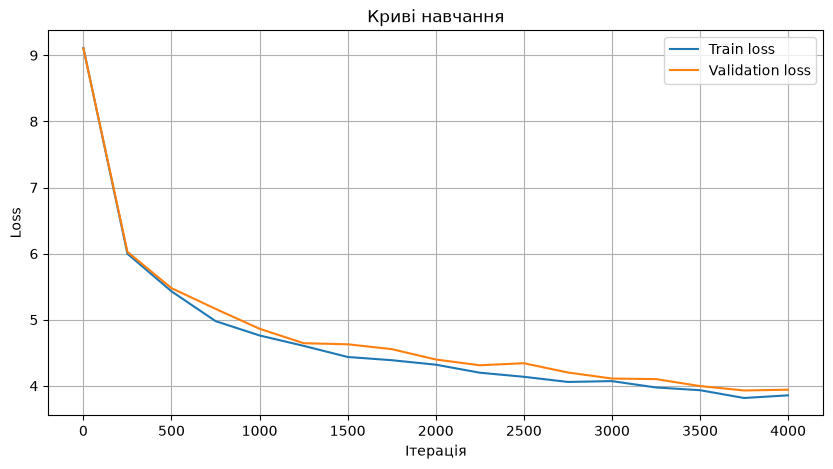

In [58]:
plt.figure(figsize=(10, 5))

plt.plot(checkpoint_iters, train_losses, label="Train loss")
plt.plot(checkpoint_iters, val_losses, label="Validation loss")

plt.xlabel("Ітерація")
plt.ylabel("Loss")
plt.title("Криві навчання")
plt.legend()
plt.grid(True)
plt.show()

# V2

In [63]:
CONTEXT_LEN = 80
EMBED_DIM = 128
N_HEADS = 4
N_LAYERS = 3
DROPOUT = 0.1
BATCH_SIZE = 32
LEARNING_RATE = 3e-4
MAX_ITERS = 4000
EVAL_INTERVAL = 250
EVAL_ITERS = 20

assert EMBED_DIM % N_HEADS == 0, \
    "EMBED_DIM має ділитися на N_HEADS"

HEAD_DIM = EMBED_DIM // N_HEADS

VOCAB_SIZE = gpt_tokenizer.get_vocab_size()

print("Параметри MiniGPT 2:")
print(f"Розмір словника: {VOCAB_SIZE}")
print(f"Довжина контексту: {CONTEXT_LEN}")
print(f"Розмір ембедингів: {EMBED_DIM}")
print(f"Кількість голів уваги: {N_HEADS}")
print(f"Кількість Transformer-блоків: {N_LAYERS}")
print(f"Розмір батчу: {BATCH_SIZE}")
print(f"Швидкість навчання: {LEARNING_RATE}")
print(f"Максимум ітерацій: {MAX_ITERS}")

Параметри MiniGPT 2:
Розмір словника: 8000
Довжина контексту: 80
Розмір ембедингів: 128
Кількість голів уваги: 4
Кількість Transformer-блоків: 3
Розмір батчу: 32
Швидкість навчання: 0.0003
Максимум ітерацій: 4000


друга версія мовної моделі 

In [64]:
model = MiniGPT(
    vocab_size=VOCAB_SIZE,
    embed_dim=EMBED_DIM,
    n_heads=N_HEADS,
    n_layers=N_LAYERS,
    context_len=CONTEXT_LEN,
    dropout=DROPOUT
).to(device)

n_params = sum(
    param.numel()
    for param in model.parameters()
)

print(f"Кількість параметрів MiniGPT v2: {n_params:,}")
print(f"Обчислювальний пристрій: {device}")

Кількість параметрів MiniGPT v2: 2,660,160
Обчислювальний пристрій: cuda


 Навчання 

In [ ]:
@torch.no_grad()
def estimate_loss():
    model.eval()
    loss_results = {}

    for split in ("train", "val"):
        batch_losses = torch.zeros(EVAL_ITERS)

        for step in range(EVAL_ITERS):
            xb, yb = get_batch(split)
            _, loss = model(xb, yb)
            batch_losses[step] = loss.item()

        loss_results[split] = batch_losses.mean().item()

    model.train()
    return loss_results

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)

writer = SummaryWriter(
    log_dir=os.path.join(RUNS_DIR, "minigpt_v2")
)

BEST_CKPT_PATH = os.path.join(
    ARTIFACT_DIR, "minigpt_v2.pt"
)

train_losses, val_losses, checkpoint_iters = [], [], []
best_val_loss = float("inf")
best_iter = None
start_time = time.time()

print("Розпочинаємо навчання MiniGPT v2...")

for it in range(MAX_ITERS):
    xb, yb = get_batch("train")
    _, loss = model(xb, yb)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    if it % EVAL_INTERVAL == 0 or it == MAX_ITERS - 1:
        losses = estimate_loss()

        train_losses.append(losses["train"])
        val_losses.append(losses["val"])
        checkpoint_iters.append(it)

        writer.add_scalar("Loss/train", losses["train"], it)
        writer.add_scalar("Loss/val", losses["val"], it)

        elapsed_min = (time.time() - start_time) / 60

        print(
            f"Крок {it:4d} | "
            f"train_loss={losses['train']:.3f} | "
            f"val_loss={losses['val']:.3f} | "
            f"час={elapsed_min:.1f} хв"
        )
        if losses["val"] < best_val_loss:
            best_val_loss = losses["val"]
            best_iter = it

            torch.save({
                "model_state_dict": model.state_dict(),
                "vocab_size": VOCAB_SIZE,
                "context_len": CONTEXT_LEN,
                "embed_dim": EMBED_DIM,
                "n_heads": N_HEADS,
                "n_layers": N_LAYERS,
                "dropout": DROPOUT,
                "best_val_loss": best_val_loss,
                "best_iter": best_iter,
            }, BEST_CKPT_PATH)

writer.close()

print("\nНавчання MiniGPT v2 завершено.")
print(f"Найкращий крок: {best_iter}")
print(f"Мінімальний val_loss: {best_val_loss:.3f}")
print(f"Файл моделі: {BEST_CKPT_PATH}")

Розпочинаємо навчання MiniGPT v2...
Крок    0 | train_loss=9.042 | val_loss=9.050 | час=0.0 хв
Крок  250 | train_loss=5.715 | val_loss=5.843 | час=0.0 хв
Крок  500 | train_loss=5.093 | val_loss=5.131 | час=0.1 хв
Крок  750 | train_loss=4.735 | val_loss=4.710 | час=0.1 хв
Крок 1000 | train_loss=4.448 | val_loss=4.510 | час=0.1 хв
Крок 1250 | train_loss=4.381 | val_loss=4.377 | час=0.2 хв
Крок 1500 | train_loss=4.099 | val_loss=4.349 | час=0.2 хв
Крок 1750 | train_loss=3.993 | val_loss=4.267 | час=0.2 хв
Крок 2000 | train_loss=4.038 | val_loss=4.125 | час=0.2 хв
Крок 2250 | train_loss=3.921 | val_loss=4.111 | час=0.3 хв
Крок 2500 | train_loss=3.843 | val_loss=3.877 | час=0.3 хв
Крок 2750 | train_loss=3.730 | val_loss=3.851 | час=0.3 хв
Крок 3000 | train_loss=3.684 | val_loss=3.891 | час=0.4 хв
Крок 3250 | train_loss=3.624 | val_loss=3.806 | час=0.4 хв
Крок 3500 | train_loss=3.582 | val_loss=3.720 | час=0.4 хв
Крок 3750 | train_loss=3.607 | val_loss=3.764 | час=0.5 хв
Крок 3999 | train_lo

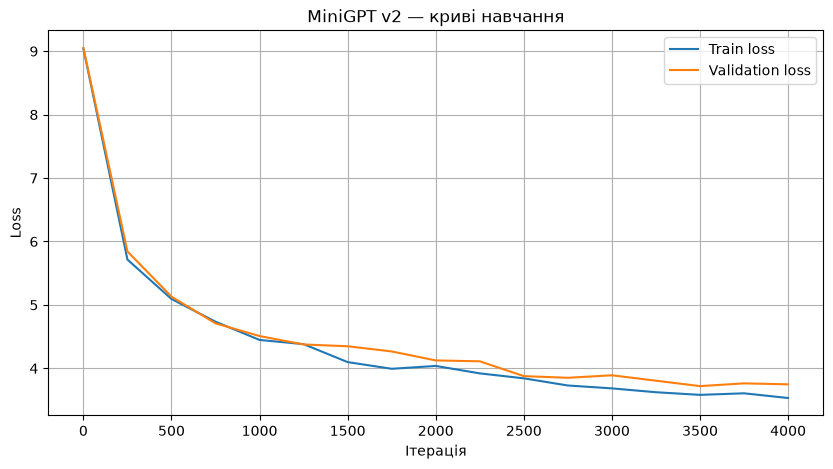

In [66]:
plt.figure(figsize=(10, 5))
plt.plot(checkpoint_iters, train_losses, label="Train loss")
plt.plot(checkpoint_iters, val_losses, label="Validation loss")

plt.xlabel("Ітерація")
plt.ylabel("Loss")
plt.title("MiniGPT v2 — криві навчання")
plt.legend()
plt.grid(True)
plt.show()

### 3.3. Генерація і висновки

Для кожного варіанта — генерація на найкращому за `val_loss` чекпоінті (демо 3.10), той самий промпт для всіх варіантів, щоб порівняння було чесним. Коротко письмово: який варіант дав кращий `val_loss` і чи помітно це за якістю згенерованого тексту? Що саме (зміна словника, глибини мережі, довжини контексту) дало найбільший ефект?

In [69]:
import os
import torch

V1_CKPT_PATH = os.path.join(ARTIFACT_DIR, "minigpt_v1.pt")
V2_CKPT_PATH = os.path.join(ARTIFACT_DIR, "minigpt_v2.pt")


def generate_text(
    checkpoint_path: str,
    prompt: str,
    max_new_tokens: int = 128,
    temperature: float = 0.8,
    top_k: int = 40,
) -> str:
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    generator = MiniGPT(
        vocab_size=checkpoint["vocab_size"],
        embed_dim=checkpoint["embed_dim"],
        n_heads=checkpoint["n_heads"],
        n_layers=checkpoint["n_layers"],
        context_len=checkpoint["context_len"],
        dropout=checkpoint["dropout"],
    ).to(device)

    generator.load_state_dict(checkpoint["model_state_dict"])
    generator.eval()

    input_ids = torch.tensor(
        [gpt_tokenizer.encode(prompt).ids],
        dtype=torch.long,
        device=device
    )
    with torch.no_grad():
        generated_ids = generator.generate(
            input_ids,
            max_new_tokens=max_new_tokens,
            temperature=temperature,
            top_k=top_k
        )

    return gpt_tokenizer.decode(generated_ids[0].tolist())


PROMPT = (
    "Потрібно розробити програму для підрахунку кількості пар у масиві. Опиши основні кроки розв'язання та запропонуй оптимальну складність алгоритму."
)

print("=== Результат MiniGPT v1 ===")
print(generate_text(V1_CKPT_PATH, PROMPT))

print("\n" + "-" * 60 + "\n")

print("=== Результат MiniGPT v2 ===")
print(generate_text(V2_CKPT_PATH, PROMPT))

=== Результат MiniGPT v1 ===
Потрібно розробити програму для підрахунку кількості пар у масиві. Опиши основні кроки розв ' язання та запропонуй оптимальну складність алгоритму. Але в цьому випадку містить два числа в одномуій до міста у зворотному порядку зростання, якщо вона має бути до відповіді, щоб обчислити всі можливі позиції ( від індексу ), то кількість цифр. Але у першому прикладі до 100. Але це може бути меншим потрібно знайти два запит, можливо, але код повинен бути. Тож код може мати дерево відрізків. Тож код обробляє значення : Аналіз завершено. Переходжу до розв ' язку. Вам надано задачу зі спортивного програмування. Analyze the maximum input constraints and identify the largest possible test cases within the largest possible test cases within a single integer by ` ` ` ` python < your code here > ` ` `

------------------------------------------------------------

=== Результат MiniGPT v2 ===
Потрібно розробити програму для підрахунку кількості пар у масиві. Опиши основні

# Висновок

MiniGPT v2 показала дещо кращий результат за val_loss: 3.748 проти 3.942 у v1, тобто приблизно на 4,0% менше.

За запитом про підрахунок кількості пар у масиві жодна модель не дала змістовної відповіді. v1 повторює шаблонні фрази з корпусу «Аналіз завершено. Переходжу до розв'язку» і окремі терміни без зв'язку між реченнями. v2 переходить до формату умови задачі input, output, Note і числових прикладів, але не описує кроків розв'язання й складності.

Обидві моделі вивчили стиль, але не вміють міркувати над змістом. Для компактних моделей це очікувано. Для кращого результату потрібні більша модель, довше навчання й більше даних.

---
## 4. Playground готових моделей

Тур по задачах через `pipeline()` — на основі [HF LLM Course, Chapter 1, §3](https://huggingface.co/learn/llm-course/en/chapter1/3).

_Зверніть увагу_: в межах попередніх завдань Ви могли завантажити памʼять "під завʼязку", тому для безпроблемного виконання наступних секцій вивільніть памʼять:

1. **Спершу збережіть усе потрібне на диск** — чекпоінти mini-GPT (`models/minigpt_v*.pt`), токенізатори, `results.csv`. Секції 4-6 від змінних секцій 1-3 не залежать, тож після цього їх можна сміливо видаляти.
2. **Видаліть великі обʼєкти** — моделі, оптимізатори, тензори `train_data`/`val_data`, корпус і `DataFrame`-и — і зберіть сміття:
   ```python
   import gc, torch

   del model, optimizer, train_data, val_data, corpus_text  # підставте свої імена змінних
   gc.collect()
   if torch.cuda.is_available():
       torch.cuda.empty_cache()
       print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")
   ```
   Памʼять звільниться лише тоді, коли на обʼєкт не лишиться **жодного** посилання: зверніть увагу на копії в інших змінних, списках і словниках (наприклад, словник із кількома варіантами моделей).
3. **Перевірте, що памʼять справді звільнилась**: індикатор RAM/GPU вгорі праворуч.
4. **У самій секції 4 не тримайте всі pipeline-и одночасно**: кожен `pipeline(...)` завантажує окрему модель. Перевикористовуйте одну змінну (як `classifier` нижче) або робіть `del` + `gc.collect()` після кожної задачі.
5. **Стежте за диском**: моделі кешуються в `~/.cache/huggingface/hub`, і кілька моделей для summarization/translation легко займуть кілька ГБ. Переглянути й почистити кеш: `hf cache ls` / `hf cache rm <id моделі>`.

# Очищення пам'яті перед роботою з готовими моделями

In [70]:
import gc
import torch

objects_to_delete = [
    "model",
    "optimizer",
    "train_data",
    "val_data",
    "data",
    "encoded_docs",
    "corpus_text",
    "poems_df",
    "dataset",
    "texts",
    "texts_list",
    "sample_texts",
    "word_list",
    "unique_words",
    "word_frequency",
    "comparison_df",
    "comparison_results",
    "bpe_tokenizer",
    "wordpiece_tokenizer",
    "unigram_tokenizer",
    "gpt_tokenizer",
    "base_tokenizer",
    "custom_qwen_tokenizer",
    "xb",
    "yb",
    "writer",
    "loss",
    "losses",
    "generated_ids",
    "output_ids",
    "prompt_ids",
    "generator",
    "checkpoint",
]

for object_name in objects_to_delete:
    if object_name in globals():
        del globals()[object_name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")
    print(f"GPU: зарезервовано {torch.cuda.memory_reserved() / 1e9:.2f} GB")
else:
    print("CUDA недоступна — кеш відеопам'яті не використовується.")

try:
    import psutil

    memory = psutil.virtual_memory()
    print(f"RAM: використано {memory.used / 1e9:.2f} GB")
    print(f"RAM: доступно {memory.available / 1e9:.2f} GB")
    print(f"RAM: загальний обсяг {memory.total / 1e9:.2f} GB")

except ImportError:
    print("Для статистики RAM встановіть бібліотеку: pip install psutil")

print("Очищення завершено.")

GPU: зайнято 0.12 GB
GPU: зарезервовано 0.20 GB
RAM: використано 22.20 GB
RAM: доступно 46.14 GB
RAM: загальний обсяг 68.34 GB
Очищення завершено.


### 4.0. Запустіть приклади виконання різних NLP задач

In [ ]:
#!pip install "transformers[sentencepiece]==5.18.0"

In [74]:
# Sentiment analysis
from transformers import pipeline

classifier = pipeline("sentiment-analysis")
print(classifier("I've been waiting for a HuggingFace course my whole life."))
print(classifier(
    ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]
))

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[{'label': 'POSITIVE', 'score': 0.9598046541213989}]
[{'label': 'POSITIVE', 'score': 0.9598046541213989}, {'label': 'NEGATIVE', 'score': 0.9994558691978455}]


In [76]:
# Zero-shot classification
from transformers import pipeline

classifier = pipeline("zero-shot-classification")
classifier(
    "This is a course about the Transformers library",
    candidate_labels=["education", "politics", "business"],
)

[transformers] No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

{'sequence': 'This is a course about the Transformers library',
 'labels': ['education', 'business', 'politics'],
 'scores': [0.8445956707000732, 0.11197683960199356, 0.04342753067612648]}

In [78]:
# Text generation
from transformers import pipeline

generator = pipeline("text-generation")
print(generator("In this course, we will teach you how to"))

generator = pipeline("text-generation", model="distilgpt2")
print(generator(
    "In this course, we will teach you how to",
    max_length=30,
    num_return_sequences=2,
))

[transformers] No model was supplied, defaulted to HuggingFaceTB/SmolLM3-3B and revision a07cc9a.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/326 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[{'generated_text': 'In this course, we will teach you how to create a basic website using HTML and CSS. You will learn the fundamental concepts of web development, including how to structure a website, add content, and style it using CSS. We will cover topics such as HTML tags, CSS selectors, and responsive design. You will also learn how to use online tools and resources to create and test your website. By the end of the course, you will have created a functional website and be able to make changes and updates to it.\nThis course is suitable for beginners who have no prior experience in web development. It is also suitable for those who want to learn web development from scratch or for those who want to refresh their knowledge.\nWhat will I learn in this course?\n- HTML basics\n- CSS basics\n- Responsive design\n- Creating a website from scratch\n- Adding content to a website\n- Styling a website with CSS\n- Testing and debugging a website\nWhat will I need to know before starting th

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[{'generated_text': "In this course, we will teach you how to use your knowledge to use your skills.\n\n\n\n\nWe will show you the information needed to start with.\nThe goal is to create something that you can use freely, with a little bit of creativity.\nYou can use your knowledge to create something that doesn't need to be mastered, or it can be used to make things very simple and easy to use.\nIt is a great way to learn how to use your skills. You can use it for other purposes.\nYou can create a project that you are looking for.\nThis course will cover your first time using the skills of your teacher.\nYou will find out how to use your skills in practice.\nIn this course, we will cover how to use your skills to make things very simple and easy to use.\nOur training will help you to learn how to use your skills.\nOur training will help you to learn how to use your skills to make things very simple and easy to use.\nOur training will help you to learn how to use your skills to make t

In [79]:
# Fill-mask
from transformers import pipeline

unmasker = pipeline("fill-mask")
unmasker("This course will teach you all about <mask> models.", top_k=2)

[transformers] No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

c:\Users\Dmytro\miniconda3\envs\bert-demo\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Dmytro\.cache\huggingface\hub\models--distilbert--distilroberta-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B /  331MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

... (2 outputs left out)

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'score': 0.1961974799633026,
  'token': 30412,
  'token_str': ' mathematical',
  'sequence': 'This course will teach you all about mathematical models.'},
 {'score': 0.04052707925438881,
  'token': 38163,
  'token_str': ' computational',
  'sequence': 'This course will teach you all about computational models.'}]

In [80]:
# Named entity recognition
from transformers import pipeline

ner = pipeline("ner", aggregation_strategy="simple")
ner("My name is Sylvain and I work at Hugging Face in Brooklyn.")

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

c:\Users\Dmytro\miniconda3\envs\bert-demo\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Dmytro\.cache\huggingface\hub\models--dbmdz--bert-large-cased-finetuned-conll03-english. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

[{'entity_group': 'PER',
  'score': np.float32(0.9981694),
  'word': 'Sylvain',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.9796019),
  'word': 'Hugging Face',
  'start': 33,
  'end': 45},
 {'entity_group': 'LOC',
  'score': np.float32(0.9932106),
  'word': 'Brooklyn',
  'start': 49,
  'end': 57}]

In [81]:
# Question answering
from transformers import pipeline

question_answerer = pipeline("table-question-answering")
question_answerer(
    query="How many stars does the transformers repository have?",
    table={"Repository":["Transformers","Datasets","Tokenizers"],"Stars":["36542","4512","3934"],"Contributors":["651","77","34"],"Programming language":["Python","Python","Rust, Python and NodeJS"]},
)

[transformers] No model was supplied, defaulted to google/tapas-base-finetuned-wtq and revision e3dde19.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.66k [00:00<?, ?B/s]

c:\Users\Dmytro\miniconda3\envs\bert-demo\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Dmytro\.cache\huggingface\hub\models--google--tapas-base-finetuned-wtq. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  443MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/154 [00:00<?, ?B/s]

{'answer': 'AVERAGE > 36542',
 'coordinates': [(0, 1)],
 'cells': ['36542'],
 'aggregator': 'AVERAGE'}

### 4.1. Свої приклади

Повторіть **усі 6 задач** вище (sentiment-analysis, zero-shot-classification, text-generation, fill-mask, NER, table-question-answering), але замість дефолтних англійських прикладів — придумайте й використайте **свої українськомовні приклади** для кожної задачі (якщо потрібно, підберіть відповідні моделі зі знанням української мови). Для виконання цього завдання постворюйте клітинки нижче.

In [ ]:
# Sentiment analysis

from transformers import pipeline

# Завантажуємо мультимовну модель для класифікації тональності
sentiment_model = pipeline(
    "sentiment-analysis",
    model="Horizon-Labs/multilingual-sentiment-small"
)

text = [
    "Як мене це все задовбало, хочу звалити додому в Японію",
]

results = sentiment_model(text)

for review, result in zip(text, results):
    print(f"Відгук: {review}")
    print(f"Мітка: {result['label']}")
    print(f"Впевненість: {result['score']:.3f}")
    print("-" * 60)

# Звільняємо пам'ять після завершення роботи
del sentiment_model

config.json:   0%|          | 0.00/2.08k [00:00<?, ?B/s]

c:\Users\Dmytro\miniconda3\envs\bert-demo\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Dmytro\.cache\huggingface\hub\models--Horizon-Labs--multilingual-sentiment-small. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B /  563MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/46.4k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 34.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

Відгук: Як мене це все задовбало, хочу звалити додому в Японію
Мітка: negative
Впевненість: 0.517
------------------------------------------------------------


In [84]:
# Zero-shot classification

from transformers import pipeline

topic_classifier = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"
)

description = (
    "Щоб приготувати яєчню потрібно яйце"
)

categories = [
    "кулінарія",
    "туторіал",
    "новини",
    "проєктування баз даних"
]

classification = topic_classifier(
    description,
    candidate_labels=categories,
    multi_label=False
)

print("Опис ситуації:", description)
print("\nРезультати класифікації:")

for category, score in zip(
    classification["labels"],
    classification["scores"]
):
    print(f"{category}: {score:.3f}")

del topic_classifier

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Опис ситуації: Щоб приготувати яєчню потрібно яйце

Результати класифікації:
кулінарія: 0.934
туторіал: 0.031
новини: 0.020
проєктування баз даних: 0.015


In [86]:
# 3. Text generation — генерація тексту

from transformers import pipeline

text_generator = pipeline(
    "text-generation",
    model="malteos/gpt2-uk"
)

prompt = (
   "Щоб приготувати яєчню потрібно яйце та"
)

generated_texts = text_generator(
    prompt,
    max_new_tokens=50,
    num_return_sequences=2,
    do_sample=True,
    temperature=0.8,
    top_k=40,
    pad_token_id=text_generator.tokenizer.eos_token_id
)

for number, result in enumerate(generated_texts, start=1):
    print(f"\nВаріант {number}:")
    print(result["generated_text"])

del text_generator

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: malteos/gpt2-uk
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
[transformers] Both `max_new_tokens` (=50) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Варіант 1:
Щоб приготувати яєчню потрібно яйце та зробити його з яєць. Для цього яйця потрібно порізати на невеликі шматочки, які мають трохи більше одного яйця. Далі яйце накрити товстим шаром і залишити на пару хвилин, потім ще раз покласти на нього яєчню, щоб яйця повністю просох

Варіант 2:
Щоб приготувати яєчню потрібно яйце та вершкове масло, яйця повинні бути нежирні, щоб не було грудочок. Для додання маскараду яєчня потрібно трохи охолодити, додати масло, що залишилося, трохи меду, яйця, додати кефір і перемішати.


In [90]:
# Fill-mask

from transformers import pipeline

mask_filler = pipeline(
    "fill-mask",
    model="FacebookAI/xlm-roberta-base"
)

masked_sentence = (
"Щоб" 
"<mask>"
"яєчню потрібно взяти яйце"

)

predictions = mask_filler(
    masked_sentence,
    top_k=5
)

print("Речення:", masked_sentence)
print("\nМожливі варіанти заповнення:")

for prediction in predictions:
    print(
        prediction["token_str"],
        "—",
        round(prediction["score"], 4)
    )

del mask_filler

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] XLMRobertaForMaskedLM LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Речення: Щоб<mask>яєчню потрібно взяти яйце

Можливі варіанти заповнення:
зробити — 0.5911
приготувати — 0.2062
додати — 0.0321
дати — 0.0262
отримати — 0.0243


In [91]:
# Named Entity Recognition

from transformers import pipeline

entity_recognizer = pipeline(
    "ner",
    model="ukr-models/uk-ner",
    aggregation_strategy="simple"
)

it_text = (
    "Компанія MiraTech розробляє платіжну систему "
    "Команда працює в Києві, "
    "а проєкт зберігається в TeamFoundation Server"
)

recognized_entities = entity_recognizer(it_text)

for entity in recognized_entities:
    print(
        f"Текст: {entity['word']} | "
        f"Тип: {entity['entity_group']} | "
        f"Впевненість: {entity['score']:.3f}"
    )

del entity_recognizer

config.json:   0%|          | 0.00/1.01k [00:00<?, ?B/s]

c:\Users\Dmytro\miniconda3\envs\bert-demo\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Dmytro\.cache\huggingface\hub\models--ukr-models--uk-ner. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B /  854kB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.37M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

Текст: Mira | Тип: ORG | Впевненість: 1.000
Текст: Tech | Тип: ORG | Впевненість: 1.000
Текст: Києві | Тип: LOC | Впевненість: 0.999
Текст: Team | Тип: ORG | Впевненість: 1.000
Текст: Fo | Тип: ORG | Впевненість: 1.000
Текст: unda | Тип: ORG | Впевненість: 1.000
Текст: tion Server | Тип: ORG | Впевненість: 0.928


In [92]:
# Table Question Answering

from transformers import pipeline

table_qa = pipeline(
    "table-question-answering",
    model="google/tapas-base-finetuned-wtq"
)

project_table = {
    "Проєкт": [
        "Інтернет-магазин",
        "Мобільний застосунок",
        "Система обліку завдань"
    ],
    "Мова": [
        "Python",
        "Kotlin",
        "JavaScript"
    ],
    "Місяці": [
        "4",
        "6",
        "3"
    ],
    "Статус": [
        "завершено",
        "у розробці",
        "тестування"
    ]
}

question = "На які мові написаний інтернет-магазин?"

answer = table_qa(
    query=question,
    table=project_table
)

print("Запитання:", question)
print("Відповідь моделі:", answer)


del table_qa

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Запитання: На які мові написаний інтернет-магазин?
Відповідь моделі: {'answer': 'Інтернет-магазин', 'coordinates': [(0, 0)], 'cells': ['Інтернет-магазин'], 'aggregator': 'NONE'}


Очищення RAM і пам'яті після роботи з моделями


In [93]:
import gc
import ctypes
import torch

objects_to_clear = [
    "classifier",
    "sentiment_model",
    "topic_classifier",
    "classification",
    "generator",
    "text_generator",
    "generated_stories",
    "generated_texts",
    "result",
    "unmasker",
    "mask_filler",
    "predictions",
    "ner",
    "entity_recognizer",
    "recognized_entities",
    "question_answerer",
    "table_qa",
    "game_description",
    "game_categories",
    "souls_reviews",
    "it_reviews",
    "it_description",
    "it_categories",
    "it_prompt",
    "it_text",
    "masked_sentence",
    "boss_table",
    "project_table",
    "table",
    "answer",
    "optimizer",
    "model",
    "train_data",
    "val_data",
    "data",
    "encoded_docs",
    "corpus_text",
    "poems_df",
    "dataset",
    "texts",
    "sample_texts",
    "gpt_tokenizer",
    "base_tokenizer",
    "custom_qwen_tokenizer",
    "bpe_tokenizer",
    "wordpiece_tokenizer",
    "unigram_tokenizer",
    "xb",
    "yb",
]

for name in objects_to_clear:
    if name in globals():
        del globals()[name]

gc.collect()


if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()


try:
    libc = ctypes.CDLL("libc.so.6")
    libc.malloc_trim(0)
except (OSError, AttributeError):
    pass

gc.collect()

try:
    import psutil

    memory = psutil.virtual_memory()

    print(f"Загальна RAM: {memory.total / 1024**3:.2f} GB")
    print(f"Використано RAM: {memory.used / 1024**3:.2f} GB")
    print(f"Доступно RAM: {memory.available / 1024**3:.2f} GB")
    print(f"Завантаження RAM: {memory.percent}%")

except ImportError:
    print("Для статистики RAM виконай: %pip install psutil")

if torch.cuda.is_available():
    print(
        f"Пам'ять GPU зайнята: "
        f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
    )
    print(
        f"Пам'ять GPU зарезервована: "
        f"{torch.cuda.memory_reserved() / 1024**3:.2f} GB"
    )
else:
    print("CUDA GPU не використовується.")

print("\nОчищення завершено.")

Загальна RAM: 63.65 GB
Використано RAM: 26.10 GB
Доступно RAM: 37.54 GB
Завантаження RAM: 41.0%
Пам'ять GPU зайнята: 0.11 GB
Пам'ять GPU зарезервована: 0.18 GB

Очищення завершено.


---
## 5. Порівняння моделей

### 5.1. Оберіть задачу й метрику

Візьміть **одну** задачу зі списку нижче:

| Задача | Метрика | Що потрібно підготувати | Метрика в `evaluate` |
|---|---|---|---|
| sentiment-analysis | Accuracy / F1 | 15-20 своїх речень + правильна мітка (positive/negative) | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy), [`f1`](https://huggingface.co/spaces/evaluate-metric/f1) |
| zero-shot-classification | Accuracy | те саме + фіксований список `candidate_labels` | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy) |
| NER | F1 (entity-level) | кілька речень + список правильних сутностей (текст + тип) | [`seqeval`](https://huggingface.co/spaces/evaluate-metric/seqeval) |

Усі метрики рахуються через бібліотеку `evaluate` (той самий автор, що й `transformers`/`datasets`):
```python
import evaluate

metric = evaluate.load("rouge")  # або "accuracy", "f1", "seqeval", "squad", "sacrebleu"
metric.compute(predictions=[...], references=[...])
```
Формат `predictions`/`references` трохи відрізняється між метриками — дивіться приклад використання на сторінці кожної метрики (посилання в таблиці) або [HF Evaluate — Quick tour](https://huggingface.co/docs/evaluate/a_quick_tour).

### 5.2. Порівняйте моделі

На обраній задачі порівняйте щонайменше 2 різні моделі на однакових вхідних прикладах — не лише значення метрики, а й швидкість інференсу та розмір моделі (кількість параметрів).

### 5.3. Поекспериментуйте з налаштуваннями

Візьміть модель, що показала кращий результат, і поекспериментуйте з її налаштуваннями (temperature/top-p/top-k для генеративних задач, поріг впевненості для класифікаційних задач тощо) — щонайменше 3 зміни, по одній за раз, щоб зрозуміти, що саме впливає на метрику. Зведіть усі спроби (модель × налаштування → значення метрики) в невелику таблицю.

Коротко письмово: яка модель і яка комбінація налаштувань дала найкращий результат за обраною метрикою, і наскільки суттєво налаштування вплинули порівняно з вибором моделі?

# 5.1. Підготовлюємо українськомовний набір даних для аналізу тональності

In [94]:
texts = [
    "Борщ вийшов дуже смачний, а подача виглядає апетитно.",
    "Рецепт простий і зрозумілий, а страва виходить ароматною.",
    "Тісто вдалося ніжним, а начинка соковита і пряна.",
    "Ресторан має чудове меню, а офіціанти привітні й уважні.",
    "Курка запечена до золотистої скоринки і дуже соковита.",
    "Десерт неймовірно смачний, а крем ніжний і не надто солодкий.",
    "Кухар швидко приготував замовлення, і все було свіжим.",
    "Суп вийшов наваристим, а спеції підібрані ідеально.",
    "Піца має хрусткий корж і багато начинки, я в захваті.",
    "Я задоволений вечерею та залюбки порекомендую цей заклад друзям.",
    "Стейк був пересмажений і жорсткий, їсти його було неможливо.",
    "Суп вийшов прісним і холодним, довелося відправити його назад.",
    "Тісто не підійшло, тому пиріг вийшов сирим і важким.",
    "Офіціант довго ігнорував нас, а замовлення принесли з запізненням.",
    "Салат був несвіжий, а після нього виникли проблеми зі шлунком.",
    "Десерт надто солодкий і приторний, доїсти його не вдалося.",
    "Борщ надмірно солоний, а м'ясо в ньому майже відсутнє.",
    "Порція замала, а ціна завищена, цей ресторан не виправдав очікувань.",
    "Рецепт незрозумілий, і страва підгоріла вже на другому кроці.",
    "У закладі брудно, а їжа смакує так, ніби її розігріли вчетверте.",
]

references = (
    ["positive"] * 10
    + ["negative"] * 10
)

assert len(texts) == len(references) == 20

print("Кількість прикладів:", len(texts))
print("Позитивних:", references.count("positive"))
print("Негативних:", references.count("negative"))


Кількість прикладів: 20
Позитивних: 10
Негативних: 10


#5.2. Порівняння двох моделей

In [82]:
%pip install -q transformers evaluate

In [97]:
import os
import gc
import time
import torch
import pandas as pd

from transformers import pipeline

MODEL_DIR = os.path.join(BASE_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

RESULTS_PATH = os.path.join(BASE_DIR, "results.csv")
os.makedirs(os.path.dirname(RESULTS_PATH), exist_ok=True)

if os.path.exists(RESULTS_PATH):
    os.remove(RESULTS_PATH)

models_to_test = [
    {
        "name": "multilingual_sentiment_small",
        "id": "Horizon-Labs/multilingual-sentiment-small"
    },
    {
        "name": "tabularisai_sentiment",
        "id": "tabularisai/multilingual-sentiment-analysis"
    }
]


def normalize_sentiment(label, id2label=None):
    label = str(label)

    if label.upper().startswith("LABEL_") and id2label:
        idx = int(label.split("_")[-1])
        label = id2label.get(idx, label)

    label = label.lower().replace("_", " ").strip()

    if "negative" in label:
        return "negative"
    if "positive" in label:
        return "positive"
    if "neutral" in label:
        return "neutral"

    return "unknown"


summary_results = []

for model_info in models_to_test:
    model_name = model_info["name"]
    model_id = model_info["id"]

    print(f"\nЗавантаження моделі: {model_id}")

    device_id = 0 if torch.cuda.is_available() else -1

    classifier = pipeline(
        "text-classification",
        model=model_id,
        device=device_id
    )
    model = classifier.model
    model.eval()

    params = sum(
        parameter.numel()
        for parameter in model.parameters()
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.perf_counter()

    outputs = classifier(
        texts,
        batch_size=4,
        truncation=True
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    id2label = model.config.id2label

    predictions = [
        normalize_sentiment(output["label"], id2label)
        for output in outputs
    ]
    scores = [float(output["score"]) for output in outputs]

    print("Мітки моделі:", sorted(set(o["label"] for o in outputs)))

    correct = [
        pred == ref for pred, ref in zip(predictions, references)
    ]
    accuracy = sum(correct) / len(references)

    skipped = [p for p in predictions if p not in {"positive", "negative"}]
    if skipped:
        print(
            f"Увага: {len(skipped)} прогнозів моделі {model_name} "
            f"не є positive/negative і враховані як помилки"
        )

    result = {
        "Модель": model_name,
        "ID моделі": model_id,
        "Задача": "sentiment-analysis",
        "Accuracy": round(accuracy, 3),
        "Час, с": round(elapsed, 3),
        "Час на речення, с": round(elapsed / len(texts), 4),
        "Параметри, млн": round(params / 1_000_000, 2)
    }

    summary_results.append(result)

    print("Accuracy:", result["Accuracy"])
    print("Час виконання:", result["Час, с"], "с")
    print("Кількість параметрів:", result["Параметри, млн"], "млн")

    model_path = os.path.join(MODEL_DIR, f"{model_name}.pt")

    torch.save(
        {
            "model_name": model_name,
            "model_id": model_id,
            "task": "sentiment-analysis",
            "predictions": predictions,
            "scores": scores,
            "references": list(references),
            "texts": list(texts),
            "metrics": result
        },
        model_path
    )

    print(f"Артефакт збережено: {model_path}")

    predictions_df = pd.DataFrame({
        "Тип тесту": ["sentiment-analysis"] * len(texts),
        "Модель": [model_name] * len(texts),
        "Речення": texts,
        "Правильна мітка": references,
        "Передбачення": predictions,
        "Оцінка": scores,
        "Accuracy": [result["Accuracy"]] * len(texts),
        "Час, с": [result["Час, с"]] * len(texts),
        "Параметри, млн": [result["Параметри, млн"]] * len(texts)
    })
    predictions_df.to_csv(
        RESULTS_PATH,
        mode="a",
        header=not os.path.exists(RESULTS_PATH),
        index=False,
        encoding="utf-8-sig"
    )
    del classifier, model, outputs
    del predictions, scores, predictions_df

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

summary_df = pd.DataFrame(summary_results)
display(summary_df)

print("\nРезультати CSV:", RESULTS_PATH)


Завантаження моделі: Horizon-Labs/multilingual-sentiment-small


Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]

Мітки моделі: ['negative', 'neutral', 'positive']
Увага: 1 прогнозів моделі multilingual_sentiment_small не є positive/negative і враховані як помилки
Accuracy: 0.9
Час виконання: 0.038 с
Кількість параметрів: 140.64 млн
Артефакт збережено: d:\Downloads\lab3\lab3Tasks\models\multilingual_sentiment_small.pt

Завантаження моделі: tabularisai/multilingual-sentiment-analysis


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Мітки моделі: ['Negative', 'Positive', 'Very Negative']
Accuracy: 0.95
Час виконання: 0.052 с
Кількість параметрів: 135.33 млн
Артефакт збережено: d:\Downloads\lab3\lab3Tasks\models\tabularisai_sentiment.pt


,Модель,ID моделі,Задача,Accuracy,"Час, с","Час на речення, с","Параметри, млн"
0,multilingual_sentiment_small,Horizon-Labs/multilingual-sentiment-small,sentiment-analysis,0.90,0.038,0.0019,140.64
1,tabularisai_sentiment,tabularisai/multilingual-sentiment-analysis,sentiment-analysis,0.95,0.052,0.0026,135.33



Результати CSV: d:\Downloads\lab3\lab3Tasks\results.csv


# Висновок

У ході роботи було порівняно дві мультимовні моделі для аналізу тональності.

Модель tabularisai/multilingual-sentiment-analysis показала вищу точність: Accuracy 0,95 проти 0,90 у Horizon-Labs/multilingual-sentiment-small. Тобто вона помилилась в одному реченні з 20, а друга модель у двох. Менша модель працює дещо швидше (0,038 с проти 0,052 с на весь набір, або 0,0019 с проти 0,0026 с на речення), але має трохи більше параметрів (140,64 млн проти 135,33 млн). Різниця в часі незначна, і між запусками вона може змінюватися, оскільки залежить від навантаження на пристрій.

Отже, tabularisai є кращим вибором, коли пріоритетом є точність, а multilingual-sentiment-small — коли важлива швидкість. Результати отримано на невеликій вибірці, тому розбіжність у 5% відповідає лише одному реченню й не є статистично значущою. Для надійнішого порівняння потрібен більший набір даних.

# Експеримент: зміна порогу впевненості

In [ ]:
import os
import gc
import time
import torch
import pandas as pd
import evaluate

from transformers import pipeline

MODEL_DIR = os.path.join(BASE_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

RESULTS_PATH = os.path.join(BASE_DIR, "results.csv")
os.makedirs(os.path.dirname(RESULTS_PATH), exist_ok=True)

accuracy_metric = evaluate.load("accuracy")

thresholds = [0.00, 0.60, 0.75, 0.90]

model_name = "tabularisai_sentiment"
model_id = "tabularisai/multilingual-sentiment-analysis"

device_id = 0 if torch.cuda.is_available() else -1

print(f"Завантаження моделі: {model_id}")

classifier = pipeline(
    "text-classification",
    model=model_id,
    device=device_id
)

model = classifier.model
model.eval()

params = sum(
    parameter.numel()
    for parameter in model.parameters()
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

start = time.perf_counter()

outputs = classifier(
    texts,
    batch_size=4,
    truncation=True
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

elapsed = time.perf_counter() - start

predictions = [
    normalize_sentiment(output["label"])
    for output in outputs
]

scores = [
    float(output["score"])
    for output in outputs
]

label_to_id = {
    "negative": 0,
    "positive": 1
}

threshold_results = []

for threshold in thresholds:
    accepted = [
        i for i, score in enumerate(scores)
        if score >= threshold
        and predictions[i] in label_to_id
    ]

    accepted_predictions = [
        label_to_id[predictions[i]] for i in accepted
    ]

    accepted_references = [
        label_to_id[references[i]] for i in accepted
    ]

    if accepted:
        accuracy = accuracy_metric.compute(
            predictions=accepted_predictions,
            references=accepted_references
        )["accuracy"]
    else:
        accuracy = None

    coverage = len(accepted) / len(texts)

    result = {
        "Модель": model_name,
        "ID моделі": model_id,
        "Задача": "sentiment-analysis",
        "Поріг впевненості": threshold,
        "Accuracy": round(accuracy, 3) if accuracy is not None else None,
        "Прийнято прогнозів": len(accepted),
        "Покриття, %": round(coverage * 100, 1),
        "Час, с": round(elapsed, 3),
        "Час на речення, с": round(elapsed / len(texts), 4),
        "Параметри, млн": round(params / 1_000_000, 2)
    }

    threshold_results.append(result)

    print(f"\nПоріг впевненості: {threshold}")
    print("Accuracy:", result["Accuracy"])
    print(f"Прийнято прогнозів: {len(accepted)} з {len(texts)}")
    print("Покриття:", result["Покриття, %"], "%")

    model_path = os.path.join(
        MODEL_DIR,
        f"{model_name}_{threshold:.2f}.pt"
    )

    torch.save(
        {
            "model_name": model_name,
            "model_id": model_id,
            "task": "sentiment-analysis",
            "threshold": threshold,
            "predictions": predictions,
            "scores": scores,
            "accepted_indices": accepted,
            "references": list(references),
            "texts": list(texts),
            "metrics": result
        },
        model_path
    )

    predictions_df = pd.DataFrame({
        "Тип тесту": ["sentiment-analysis"] * len(texts),
        "Модель": [model_name] * len(texts),
        "ID моделі": [model_id] * len(texts),
        "Поріг впевненості": [threshold] * len(texts),
        "Речення": texts,
        "Правильна мітка": references,
        "Передбачення": predictions,
        "Оцінка": scores,
        "Прогноз прийнято": [
            i in accepted for i in range(len(texts))
        ],
        "Accuracy": [result["Accuracy"]] * len(texts),
        "Покриття, %": [result["Покриття, %"]] * len(texts),
        "Час, с": [result["Час, с"]] * len(texts),
        "Параметри, млн": [result["Параметри, млн"]] * len(texts)
    })

    if os.path.exists(RESULTS_PATH):
        old_df = pd.read_csv(RESULTS_PATH)
        combined_df = pd.concat(
            [old_df, predictions_df],
            ignore_index=True,
            sort=False
        )
    else:
        combined_df = predictions_df

    combined_df.to_csv(
        RESULTS_PATH,
        index=False,
        encoding="utf-8-sig"
    )

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df)

print("\nРезультати CSV:", RESULTS_PATH)

del classifier, model, outputs
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


Завантаження моделі: tabularisai/multilingual-sentiment-analysis


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


Поріг впевненості: 0.0
Accuracy: 0.95
Прийнято прогнозів: 20 з 20
Покриття: 100.0 %

Поріг впевненості: 0.6
Accuracy: 1.0
Прийнято прогнозів: 16 з 20
Покриття: 80.0 %

Поріг впевненості: 0.75
Accuracy: 1.0
Прийнято прогнозів: 10 з 20
Покриття: 50.0 %

Поріг впевненості: 0.9
Accuracy: 1.0
Прийнято прогнозів: 4 з 20
Покриття: 20.0 %


,Модель,ID моделі,Задача,Поріг впевненості,Accuracy,Прийнято прогнозів,"Покриття, %","Час, с","Час на речення, с","Параметри, млн"
0,tabularisai_sentiment,tabularisai/multilingual-sentiment-analysis,sentiment-analysis,0.00,0.95,20,100.0,0.106,0.0053,135.33
1,tabularisai_sentiment,tabularisai/multilingual-sentiment-analysis,sentiment-analysis,0.60,1.00,16,80.0,0.106,0.0053,135.33
2,tabularisai_sentiment,tabularisai/multilingual-sentiment-analysis,sentiment-analysis,0.75,1.00,10,50.0,0.106,0.0053,135.33
3,tabularisai_sentiment,tabularisai/multilingual-sentiment-analysis,sentiment-analysis,0.90,1.00,4,20.0,0.106,0.0053,135.33



Результати CSV: d:\Downloads\lab3\lab3Tasks\results.csv


# Висновок

Для моделі tabularisai/multilingual-sentiment-analysis було досліджено вплив порогу впевненості на якість класифікації. Без порогу (0,00) модель обробила всі 20 відгуків з Accuracy 0,95. Зі зростанням порогу до 0,60, 0,75 та 0,90 покриття зменшувалось до 80%, 50% та 20%, а Accuracy зросла до 1,00. Отже, підвищення порогу дозволяє отримати надійніші прогнози, але ціною того, що частина відгуків лишається без автоматичної оцінки. Оптимальним компромісом на цьому наборі є поріг 0,60: він прибирає помилковий прогноз і зберігає покриття 80%. Через малий розмір вибірки (20 прикладів) результати мають орієнтовний характер, і для надійних висновків потрібен більший набір даних.

---
## 6. Творчий застосунок

Побудуйте невеликий Gradio-застосунок на основі будь-якої готової моделі з розділів 4-5 — тема й формат повністю на ваш вибір, заохочується творчість і щось не зовсім очевидне (не просто "ще один чат-бот"). Це може бути й генеративна LLM через `transformers` (`AutoModelForCausalLM`/`AutoTokenizer` або `pipeline("text-generation", ...)`, той самий патерн, що й у демо 4.1-4.2 на Qwen) — `text-generation` уже входить до обов'язкових 8 задач розділу 4, тож це не вихід за межі завдання. Головне — щоб застосунок реально запускався і демонстрував конкретну, зрозумілу користувацьку цінність.

In [102]:
import gradio as gr
import torch
from transformers import pipeline

MODEL_ID = "tabularisai/multilingual-sentiment-analysis"

device_id = 0 if torch.cuda.is_available() else -1
sentiment_pipe = pipeline(
    "text-classification",
    model=MODEL_ID,
    device=device_id,
    top_k=None
)

LEVELS = {
    "very negative": 1,
    "negative": 2,
    "neutral": 3,
    "positive": 4,
    "very positive": 5,
}

MOOD_NAMES = {
    1: "дуже сумний",
    2: "сумний",
    3: "нейтральний",
    4: "добрий",
    5: "піднесений",
}

SONGS = [
    {"title": "Theme from Schindler's List", "artist": "John Williams", "genre": "Сумна скрипка", "valence": 1.2},
    {"title": "Méditation (Thaïs)", "artist": "Jules Massenet", "genre": "Сумна скрипка", "valence": 1.8},
    {"title": "Winter: Largo", "artist": "Antonio Vivaldi", "genre": "Сумна скрипка", "valence": 2.2},
    {"title": "Ave Maria (violin)", "artist": "Franz Schubert", "genre": "Сумна скрипка", "valence": 2.6},

    {"title": "Apologize", "artist": "OneRepublic", "genre": "OneRepublic", "valence": 1.7},
    {"title": "Secrets", "artist": "OneRepublic", "genre": "OneRepublic", "valence": 2.8},
    {"title": "Stop and Stare", "artist": "OneRepublic", "genre": "OneRepublic", "valence": 3.2},
    {"title": "I Lived", "artist": "OneRepublic", "genre": "OneRepublic", "valence": 4.0},
    {"title": "Counting Stars", "artist": "OneRepublic", "genre": "OneRepublic", "valence": 4.4},
    {"title": "Good Life", "artist": "OneRepublic", "genre": "OneRepublic", "valence": 4.8},

    {"title": "Demons", "artist": "Imagine Dragons", "genre": "Imagine Dragons", "valence": 2.0},
    {"title": "Bones", "artist": "Imagine Dragons", "genre": "Imagine Dragons", "valence": 2.9},
    {"title": "Radioactive", "artist": "Imagine Dragons", "genre": "Imagine Dragons", "valence": 3.2},
    {"title": "Enemy", "artist": "Imagine Dragons", "genre": "Imagine Dragons", "valence": 3.4},
    {"title": "Believer", "artist": "Imagine Dragons", "genre": "Imagine Dragons", "valence": 3.9},
    {"title": "Thunder", "artist": "Imagine Dragons", "genre": "Imagine Dragons", "valence": 4.3},

    {"title": "At Doom's Gate", "artist": "Mick Gordon", "genre": "DOOM OST", "valence": 3.4},
    {"title": "BFG Division", "artist": "Mick Gordon", "genre": "DOOM OST", "valence": 3.8},
    {"title": "Rip & Tear", "artist": "Mick Gordon", "genre": "DOOM OST", "valence": 4.2},
    {"title": "The Only Thing They Fear Is You", "artist": "Mick Gordon", "genre": "DOOM OST", "valence": 4.6},
]

GENRES = ["Усі збірки"] + sorted({song["genre"] for song in SONGS})

def detect_mood(text):
    result = sentiment_pipe(text, truncation=True)
    if result and isinstance(result[0], list):
        result = result[0]

    probs = {}
    for item in result:
        label = item["label"].lower().replace("_", " ").strip()
        if label in LEVELS:
            probs[LEVELS[label]] = float(item["score"])

    total = sum(probs.values()) or 1.0
    valence = sum(level * p for level, p in probs.items()) / total
    return valence, probs

def bar(value, width=20):
    filled = int(round(value * width))
    return "█" * filled + "░" * (width - filled)

def recommend(text, mode, genre, count):
    if not text.strip():
        return "Опишіть, як минув ваш день."

    valence, probs = detect_mood(text)
    mood_level = int(round(valence))

    if mode == "Підняти настрій":
        target = min(5.0, valence + 1.5)
    else:
        target = valence

    candidates = [
        song for song in SONGS
        if genre == "Усі збірки" or song["genre"] == genre
    ]
    candidates.sort(key=lambda song: abs(song["valence"] - target))
    chosen = candidates[:int(count)]

    output = [
        f"# 🎧 Ваш настрій: {MOOD_NAMES[mood_level]}",
        f"**Індекс настрою:** {valence:.2f} з 5  ",
        f"**Режим:** {mode}\n",
    ]

    for level in sorted(probs):
        name = MOOD_NAMES[level].split()[-1]
        output.append(f"- {name} `{bar(probs[level])}` {probs[level]:.0%}")

    output.append("\n### Плейлист")

    if not chosen:
        output.append("Для цієї збірки немає треків.")
    else:
        for number, song in enumerate(chosen, start=1):
            output.append(
                f"{number}. **{song['title']}** — {song['artist']} "
                f"*({song['genre']})*"
            )

    return "\n".join(output)


with gr.Blocks(title="MoodMix") as demo:
    

    text_input = gr.Textbox(
        label="Як минув ваш день?",
        lines=3
    )

    with gr.Row():
        mode_input = gr.Radio(
            choices=["Відповідати настрою", "Підняти настрій"],
            value="Відповідати настрою",
            label="Режим"
        )
        genre_input = gr.Dropdown(
            choices=GENRES,
            value="Усі збірки",
            label="Збірка"
        )
        count_input = gr.Slider(
            minimum=3,
            maximum=10,
            value=5,
            step=1,
            label="Кількість треків"
        )

    button = gr.Button("Підібрати музику", variant="primary")
    output_md = gr.Markdown()

    button.click(
        fn=recommend,
        inputs=[text_input, mode_input, genre_input, count_input],
        outputs=output_md
    )



demo.launch()

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

* Running on local URL:  http://127.0.0.1:7863
* To create a public link, set `share=True` in `launch()`.


---
### Як здавати лабу

У [форму](https://forms.gle/Z1gxmsDs656jqsDGA) здати посилання на **публічний** репозиторій, який містить:

1. **Демо-ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
3. **Файли всіх натренованих варіантів mini-GPT** (3.2) — кожен окремим `.pt` файлом.
4. **Логи TensorBoard** — папка `runs/` з усіма прогонами (і mini-GPT, і, за бажання, логи порівняння в розділі 5).
5. **Таблицю результатів** — `results.csv` з порівнянням варіантів mini-GPT (val_loss) і моделей з розділу 5.
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab3/transformers_demo.ipynb
/lab3/transformers_task.ipynb
/lab3/models/minigpt_v1.pt
/lab3/models/minigpt_v2.pt
/lab3/models/...        (усі інші варіанти з 3.2)
/lab3/runs/*
/lab3/results.csv
```